In [25]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score

# 1. Load Data


In [12]:
DATA_PATH = "../data/processed/jigsaw_clean.parquet"
BLOCKLIST_PATH = "../data/blocklist/ldnoobw_en.txt"
PRED_DIR = "../results/predictions/blocklist"

In [13]:
MAIN_IDENTITIES = [
    "male", "female", "homosexual_gay_or_lesbian", "christian", "jewish",
    "muslim", "black", "white", "psychiatric_or_mental_illness",
]

In [14]:
df = pd.read_parquet(DATA_PATH, columns=["id", "comment_text", "label", "split"] + MAIN_IDENTITIES)

In [15]:
test = df[df["split"] == "test"].reset_index(drop=True)
del df

print(f"Test comments: {len(test):,}")
print(f"Toxic: {test['label'].mean() * 100:.2f}%")

Test comments: 177,635
Toxic: 7.98%


**Note:** the blocklist has no parameters to fit, so it needs no training or validation set. To compare it with the other models, it is evaluated only on the test set.

# 2. Blocklist

We use the English list from [LDNOOBW](https://github.com/LDNOOBW/List-of-Dirty-Naughty-Obscene-and-Otherwise-Bad-Words) (List of Dirty, Naughty, Obscene and Otherwise Bad Words), a public list used in real content filters. It is used exactly as downloaded.

Before applying it, we check its size, how many entries are multi-word expressions, and which entries relate to identity terms.


In [16]:
with open(BLOCKLIST_PATH) as f:
    blocklist = sorted({line.strip().lower() for line in f if line.strip()})

multi_word = [w for w in blocklist if " " in w]

print(f"Entries: {len(blocklist)}")
print(f"Multi-word expressions: {len(multi_word)} ({len(multi_word) / len(blocklist) * 100:.1f}%)")
print(f"Examples: {multi_word[:5]}")


Entries: 403
Multi-word expressions: 124 (30.8%)
Examples: ['2 girls 1 cup', 'alabama hot pocket', 'alaskan pipeline', 'auto erotic', 'baby batter']


In [17]:
identity_terms = ["gay", "lesbian", "homo", "queer", "trans", "jew", "muslim", "islam",
                  "christian", "black", "white", "nigga", "woman", "women", "girl", "female", "male"]

counts = {term: sum(term in w for w in blocklist) for term in identity_terms}
pd.Series(counts, name="entries").loc[lambda s: s > 0].sort_values(ascending=False)

girl      12
male       3
black      2
white      2
gay        1
nigga      1
homo       1
women      1
female     1
Name: entries, dtype: int64

# 3. Applying the Blocklist

Each comment is lowercased and scanned with a single regular expression that contains all list entries.

A match only counts when it is a whole word or expression: the word boundary `\b` requires a non-letter on both sides, so "ass" does not match inside "class" or "assistant", while multi-word entries such as "blow job" are matched as a whole.

The score of a comment is the number of matches, and it is **blocked** when the score is at least 1.

In [18]:
# longer entries for match
entries = sorted(blocklist, key=len, reverse=True)
pattern = re.compile(r"\b(?:" + "|".join(re.escape(w) for w in entries) + r")\b")

text = test["comment_text"].str.lower()
test["score"] = text.str.count(pattern)
test["blocked"] = (test["score"] >= 1).astype(int)

print(f"Blocked comments: {test['blocked'].sum():,} ({test['blocked'].mean() * 100:.2f}%)")
print(test["score"].value_counts().sort_index().head(6))


Blocked comments: 5,113 (2.88%)
score
0    172522
1      4054
2       686
3       193
4        95
5        36
Name: count, dtype: int64


# 4. Entries That Block the Most

For each list entry we count the test comments it blocks and how many of them are actually toxic.

Entries with a low toxic share mostly block non-toxic comments, so they are the main source of false positives (overall toxic rate: 7.98%).

In [19]:
blocked = test[test["blocked"] == 1]
matches = blocked.assign(entry=text[blocked.index].str.findall(pattern)).explode("entry")
matches = matches.drop_duplicates(["id", "entry"])  # count each comment once per entry

by_entry = matches.groupby("entry").agg(blocked=("label", "size"), toxic=("label", "sum"))
by_entry["non_toxic"] = by_entry["blocked"] - by_entry["toxic"]
by_entry["toxic (%)"] = (by_entry["toxic"] / by_entry["blocked"] * 100).round(1)

print(f"Entries that appear at least once: {len(by_entry)} of {len(blocklist)}")
by_entry.sort_values("blocked", ascending=False).head(20)

Entries that appear at least once: 164 of 403


,blocked,toxic,non_toxic,toxic (%)
entry,,,,
sexual,1172,181,991,15.4
sex,1046,195,851,18.6
rape,516,119,397,23.1
butt,205,74,131,36.1
ass,205,153,52,74.6
suck,203,75,128,36.9
sexually,197,50,147,25.4
sucks,176,58,118,33.0
dick,175,43,132,24.6


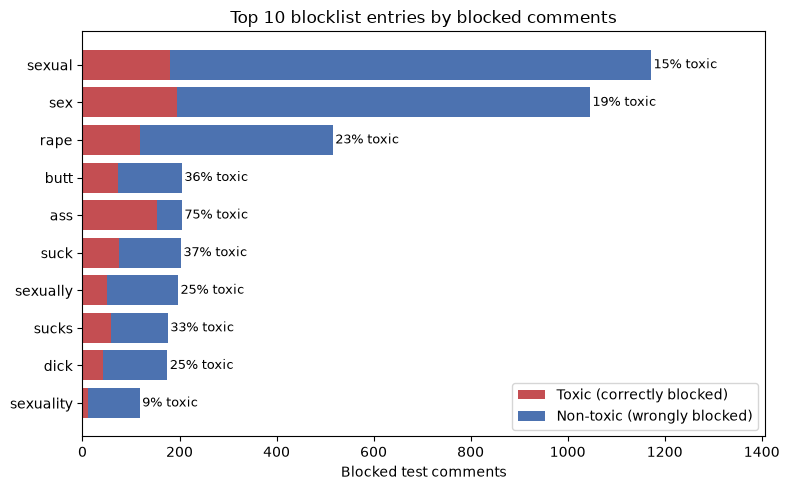

In [20]:
top10 = by_entry.sort_values("blocked", ascending=False).head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top10.index, top10["toxic"], color="#C44E52", label="Toxic (correctly blocked)")
ax.barh(top10.index, top10["non_toxic"], left=top10["toxic"], color="#4C72B0", label="Non-toxic (wrongly blocked)")

for i, (n, pct) in enumerate(zip(top10["blocked"], top10["toxic (%)"])):
    ax.text(n + 5, i, f"{pct:.0f}% toxic", va="center", fontsize=9)

ax.set_xlabel("Blocked test comments")
ax.set_title("Top 10 blocklist entries by blocked comments")
ax.set_xlim(0, top10["blocked"].max() * 1.2)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()



# 5. Evaluation


## 5.1 Confusion Matrix

Blocklist decision against the true label on the test set, with the toxic class first.

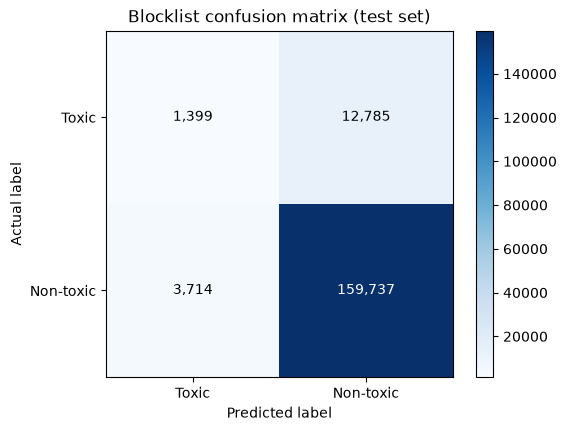

In [21]:
order = [1, 0]  # toxic first
counts = pd.crosstab(test["label"], test["blocked"]).reindex(index=order, columns=order, fill_value=0)

fig, ax = plt.subplots(figsize=(6, 4.5))
im = ax.imshow(counts, cmap="Blues")
fig.colorbar(im, ax=ax)
for (i, j), n in np.ndenumerate(counts.values):
    ax.text(j, i, f"{n:,}", ha="center", va="center", color="white" if n > counts.values.max() / 2 else "black")
ax.set_xticks([0, 1], ["Toxic", "Non-toxic"])
ax.set_yticks([0, 1], ["Toxic", "Non-toxic"])
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
ax.set_title("Blocklist confusion matrix (test set)")
plt.show()

**Conclusions:**

- **Non-toxic class:** the blocklist lets through almost all non-toxic comments (159,737, 97.7%). Only 3,714 (2.3%) are wrongly blocked.
- **Toxic class:** it detects only **1,399 toxic comments (9.9%)**; the other 12,785 (90.1%) are published.
- **Why:** the list targets sexual and obscene vocabulary, but the most frequent toxic words in Jigsaw are common insults (*idiot*, *stupid*, *moron*) that are not in the list.

In [22]:
n_blocked = test["blocked"].sum()

print(f"Comments marked as toxic by the blocklist: {n_blocked:,} of {len(test):,} ({n_blocked / len(test) * 100:.2f}%)")
print(f"Comments that are actually toxic: {test['label'].sum():,} ({test['label'].mean() * 100:.2f}%)")


Comments marked as toxic by the blocklist: 5,113 of 177,635 (2.88%)
Comments that are actually toxic: 14,184 (7.98%)


## 5.2 Precision, Recall and F1

- **Precision**: of all the comments labeled as toxic, how many were actually toxic.

$$\text{Precision} = \frac{TP}{TP + FP}$$

- **Recall**: of all the comments that were actually toxic, how many were identified.

$$\text{Recall} = \frac{TP}{TP + FN}$$

- **F1**: mean of precision and recall

$$F_1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$

In this project we prioritize **recall**: a toxic comment that is published does more harm than a non-toxic comment that is flagged as toxic and sent to human review.


In [ ]:
y_true, y_pred = test["label"], test["blocked"]

metrics = pd.Series({
    "precision": precision_score(y_true, y_pred),
    "recall": recall_score(y_true, y_pred),
    "f1": f1_score(y_true, y_pred),
    "fpr": ((y_pred == 1) & (y_true == 0)).sum() / (y_true == 0).sum(),
    "fnr": ((y_pred == 0) & (y_true == 1)).sum() / (y_true == 1).sum(),
}).round(3)
metrics


precision    0.274
recall       0.099
f1           0.145
fpr          0.023
fnr          0.901
dtype: float64

## 5.3 Results by Identity Subgroup

For each of the 9 identity subgroups (identity value >= 0.5) we compute three metrics and compare them with the whole test set:

- **Accuracy on toxic comments**: of all the toxic comments in the subgroup, how many are detected.

$$\text{Acc}_{\text{toxic}} = \frac{TP}{TP + FN}$$

- **Accuracy on non-toxic comments**: of all the non-toxic comments in the subgroup, how many are let through.

$$\text{Acc}_{\text{non-toxic}} = \frac{TN}{TN + FP}$$

- **False positive rate (FPR)**: of all the non-toxic comments in the subgroup, how many are wrongly marked as toxic.

$$\text{FPR} = \frac{FP}{FP + TN} = 1 - \text{Acc}_{\text{non-toxic}}$$

A subgroup is biased when it departs from the whole test set: 
-  lower accuracy on non-toxic comments means its innocent comments are blocked more often
-  lower accuracy on toxic comments means attacks on it are missed more often.



In [27]:
def group_metrics(mask):
    y_true, y_pred = test.loc[mask, "label"], test.loc[mask, "blocked"]
    return {
        "comments": int(mask.sum()),
        "toxic": int(y_true.sum()),
        "acc toxic": ((y_pred == 1) & (y_true == 1)).sum() / (y_true == 1).sum(),
        "acc non-toxic": ((y_pred == 0) & (y_true == 0)).sum() / (y_true == 0).sum(),
        "fpr": ((y_pred == 1) & (y_true == 0)).sum() / (y_true == 0).sum(),
    }

rows = {"all (test)": group_metrics(pd.Series(True, index=test.index))}
for name in MAIN_IDENTITIES:
    rows[name] = group_metrics(test[name] >= 0.5)

by_group = pd.DataFrame(rows).T
by_group[["comments", "toxic"]] = by_group[["comments", "toxic"]].astype(int)
cols = ["acc toxic", "acc non-toxic", "fpr"]
by_group[cols] = (by_group[cols] * 100).round(1)
by_group



,comments,toxic,acc toxic,acc non-toxic,fpr
all (test),177635,14184,9.9,97.7,2.3
male,4382,672,22.8,88.4,11.6
female,5188,702,29.2,85.1,14.9
homosexual_gay_or_lesbian,1071,307,27.4,77.2,22.8
christian,3888,406,16.5,92.8,7.2
jewish,686,127,7.9,95.0,5.0
muslim,2017,481,6.2,96.7,3.3
black,1478,474,9.5,93.7,6.3
white,2436,696,8.0,95.9,4.1
psychiatric_or_mental_illness,445,98,3.1,96.3,3.7


- The most biased subgroups are **homosexual_gay_or_lesbian**, **female** and **male**: the blocklist wrongly marks as toxic 22.8%, 14.9% and 11.6% of their non-toxic comments, against 2.3% overall 





Since the list is mostly sexual vocabulary, comments that discuss gender or sexual orientation in a neutral way (for example "same-sex marriage" or "sexual harassment") are blocked much more often.

The opposite error appears in *muslim*, *jewish*, *white* and *psychiatric_or_mental_illness*: fewer toxic comments are detected than overall, because attacks on these groups rarely use obscene words.


## 5.4 Error Examples


In [29]:
pd.set_option("display.max_colwidth", 200)

false_pos = test[(test["blocked"] == 1) & (test["label"] == 0)].sample(3, random_state=42)
false_pos = false_pos.assign(entry=text[false_pos.index].str.findall(pattern).str.join(", "))
print("False positives: non-toxic comments that were blocked")
display(false_pos[["comment_text", "entry"]])

false_neg = test[(test["blocked"] == 0) & (test["label"] == 1)].sample(3, random_state=42)
print("False negatives: toxic comments that were not blocked")
display(false_neg[["comment_text"]])


False positives: non-toxic comments that were blocked


,comment_text,entry
148579,"John, in his book with Rabbi Skorka before he became pope, Cardinal Bergoglio told of a bishop who consulted him over a paedophile priest and his advice was to take away the priest’s faculties and...",paedophile
32221,Convenience is a legal option in the first trimester. I have not been able to respond to your last reply to me because it isn't here. So I'll take this opportunity. My job is to protect my chil...,rape
12032,"I completely agree with that!!!!! If you rape or molest a child you only get months or a few years, if you produce and traffic child porn you get a longer sentence. If you are an addict because yo...","rape, porn, sexual"


False negatives: toxic comments that were not blocked


,comment_text
100087,"Dave Shapiro's Grand Larceny would be if all the planning, time, construction, and billions already spent on the metro project were thrown down the toilet making the metro project useless and a to..."
30650,Now that he's used up America's racists and bigots to get elected el presidente he can throw 'em all in the trash where they belong. And he knew it all along. What a guy.
44946,This will just force Canada to set up alternative trading arrangements. Angry white men often make terrible decisions.


## 5.5 Probe Sentences

Hand-written sentences shared by all models (`data/probe_sentences.csv`)


In [33]:
probes = pd.read_csv("../data/probe_sentences.csv")

probes["model result"] = probes["sentence"].str.lower().str.contains(pattern).map({True: "toxic", False: "non-toxic"})
probes = probes.rename(columns={"expected": "target"})
probes["correct"] = (probes["model result"] == probes["target"]).map({True: "yes", False: "no"})

for category, group in probes.groupby("category", sort=False):
    print(f"\n{category}")
    display(group[["sentence", "target", "model result", "correct"]].reset_index(drop=True))



negation with insult


,sentence,target,model result,correct
0,You are an idiot,toxic,non-toxic,no
1,You are not an idiot,non-toxic,non-toxic,yes
2,You are stupid,toxic,non-toxic,no
3,You are not stupid,non-toxic,non-toxic,yes



negation without insult


,sentence,target,model result,correct
0,I hate gay people,toxic,non-toxic,no
1,I don't hate gay people,non-toxic,non-toxic,yes
2,Black people are criminals,toxic,non-toxic,no
3,Black people are not criminals,non-toxic,non-toxic,yes



identity mention


...

,sentence,target,model result,correct
0,Calling someone an idiot is not okay,non-toxic,non-toxic,yes
1,Saying gay people are disgusting is hateful,non-toxic,non-toxic,yes



profanity


,sentence,target,model result,correct
0,This movie is fucking amazing,non-toxic,toxic,no
1,Holy shit what a great game,non-toxic,toxic,no



word order


,sentence,target,model result,correct
0,You are an idiot and I am right,toxic,non-toxic,no
1,I am an idiot and you are right,non-toxic,non-toxic,yes


**Conclusions:**

- The list is mostly obscene and sexual vocabulary, so **none of the toxic probe sentences is blocked*

- Errors appear wherever a list word is used in a harmless context: "Same-sex marriage should be legal" (*sex*), "She reported the sexual harassment to the police" (*sexual*)

- The correct answers on negations ("You are not an idiot") are not a sign of understanding: the blocklist marks every sentence without a list word as non-toxic, so it also misses the affirmative versions.


## 5.6 Saving Predictions


In [34]:
import os

os.makedirs(PRED_DIR, exist_ok=True)
test[["id", "label", "blocked", "score"]].to_parquet(f"{PRED_DIR}/test.parquet", index=False)
print(f"Saved {len(test):,} predictions to {PRED_DIR}/test.parquet")


Saved 177,635 predictions to ../results/predictions/blocklist/test.parquet
